> 📘 **풀이를 채운 로컬 GPU 실행용 노트북입니다.** 채점 셀은 실행할 때 검증합니다.

# 생성형 인공지능 실습 — ChatGPT와 생성 인공지능

**대상**: 전공 4학년 · **환경**: 로컬 Python + NVIDIA CUDA GPU · **필요 라이브러리**: `numpy`, `matplotlib` (Colab 기본 제공)

강의자료 「ChatGPT와 생성 인공지능」의 핵심 개념을 **직접 코드로 구현**하며 검증하는 실습입니다.
외부 API 키나 대용량 모델 다운로드 없이 전부 실행됩니다.

| # | 주제 | 강의자료 대응 | 난이도 |
|---|------|--------------|--------|
| 1 | 거대 언어 모델의 손실 함수와 디코딩 | 어휘사전 / 다음 토큰 예측 | ★★☆☆☆ |
| 2 | Self-Attention과 O(T²) 계산량 | 트랜스포머의 관계 설정 | ★★★☆☆ |
| 3 | 정밀도 표현과 4비트 양자화 | 모델 경량화 (정밀도 / 양자화) | ★★★★☆ |
| 4 | 가지치기와 지식 증류 | 모델 경량화 (Pruning / KD) | ★★★★☆ |
| 5 | 선형 트랜스포머 (커널 근사) | 트랜스포머 대안 | ★★★★☆ |
| 6 | RetNet 리텐션: 병렬 = 재귀 | 불가능한 삼각형 / RetNet | ★★★★★ |
| 7 | RAG와 환각 효과 완화 | 환각 완화의 기본적 접근 | ★★★☆☆ |

---
### 제출 방법
1. `setup_gpu.ps1` 설치 후 `.venv` 커널에서 **모두 실행**
2. 각 문제 끝의 `채점` 셀이 모두 `통과`로 나오는지 확인
3. 서술형(📝) 답안도 코드 셀에서 출력하도록 포함
4. `.ipynb` 파일로 내려받아 제출


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time, re, math

np.set_printoptions(precision=4, suppress=True, linewidth=120)
RNG = np.random.default_rng(20250818)

# 채점 도우미 -------------------------------------------------------------
_score = {}
def check(name, cond, msg=""):
    ok = bool(cond)
    _score[name] = ok
    print(f"[{'통과' if ok else '실패'}] {name}" + (f"  <- {msg}" if (msg and not ok) else ""))
    return ok

def report():
    tot, ok = len(_score), sum(_score.values())
    print("=" * 52)
    print(f"채점 결과: {ok} / {tot} 통과")
    for k, v in _score.items():
        if not v: print("  ✗ 미통과:", k)
    print("=" * 52)

print("준비 완료 · numpy", np.__version__)


from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'assignment_runtime.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'assignment_runtime.py').exists():
    raise RuntimeError('프로젝트 루트 또는 week12/week13에서 실행하세요.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from assignment_runtime import configure, benchmark, matmul_benchmark
torch, DEVICE = configure(seed=42)

준비 완료 · numpy 2.5.4
PyTorch 2.11.0+cu128 | CUDA runtime 12.8 | device cuda
NVIDIA GeForce RTX 4070 Ti SUPER | VRAM 16.0 GiB


---
# 문제 1. 거대 언어 모델의 단순한 손실 함수와 디코딩 전략
**(강의자료: "거대 언어 모델의 단순한 손실 함수" / "어휘사전")**

> 거대 언어 모델의 출력은 **어휘 사전의 모든 토큰에 대한 확률값**이고, 이것에 의거하여 다음 토큰을 예측한다.
> 출력 확률값과 실젯값의 차이를 통해 모델을 학습한다.

즉 LLM은 결국 **어휘 사전 크기 V짜리 다중 클래스 분류기**를 시퀀스 길이만큼 반복하는 것입니다.
이 문제에서는 그 손실 함수(Cross Entropy)와 평가 지표(Perplexity), 그리고 실제 텍스트 생성에 쓰이는
디코딩 전략(greedy / temperature / top-k)을 직접 구현합니다.

### 1-1. `softmax`, `cross_entropy`, `perplexity` 구현
- $\text{softmax}(z)_i = \dfrac{e^{z_i - \max z}}{\sum_j e^{z_j - \max z}}$ (오버플로 방지를 위해 최댓값을 뺍니다)
- $\mathcal{L}_{CE} = -\log p_{\text{target}}$
- $\text{PPL} = \exp\!\left(\frac{1}{N}\sum_n \mathcal{L}^{(n)}_{CE}\right)$


In [2]:
VOCAB = ['a', 'at', 'am', 'I', '##ing', 'study', 'Transformer', '.', 'unknown']
V = len(VOCAB)
STOI = {w: i for i, w in enumerate(VOCAB)}
def softmax(z, axis=-1):
    z = np.asarray(z, dtype=np.float64)
    e = np.exp(z-z.max(axis=axis, keepdims=True))
    return e/e.sum(axis=axis, keepdims=True)
def cross_entropy(logits, target_id):
    # log-sum-exp는 극단적인 logit에서도 확률 underflow 없이 CE를 계산한다.
    logits = np.asarray(logits, dtype=np.float64)
    shifted = logits-logits.max()
    return float(np.log(np.exp(shifted).sum())-shifted[target_id])
def perplexity(logits_seq, target_ids):
    if len(target_ids) == 0:
        raise ValueError('nonempty target sequence required')
    return float(np.exp(np.mean([cross_entropy(z,t) for z,t in zip(logits_seq,target_ids, strict=True)])))
print('V=', V)

V= 9


### 1-2. 디코딩 전략 구현

강의자료의 "다음 토큰(단어)을 확률에 의거하여 학습" 이라는 서술은 **추론 시에도** 그대로 적용됩니다.
같은 로짓이라도 어떻게 뽑느냐에 따라 결과가 달라집니다.

| 전략 | 설명 |
|---|---|
| greedy | 확률이 가장 큰 토큰 하나를 고름 (결정적) |
| temperature $\tau$ | $z/\tau$ 로 로짓을 스케일. $\tau\!\to\!0$ 이면 greedy, $\tau$ 가 크면 균등분포에 가까워짐 |
| top-k | 상위 $k$ 개 토큰만 남기고 나머지는 $-\infty$ 로 마스킹한 뒤 샘플링 |


In [3]:
def decode_next(logits, temperature=1.0, top_k=None, rng=None):
    logits = np.asarray(logits, dtype=np.float64)
    rng = RNG if rng is None else rng
    if temperature is None or temperature <= 0:
        return int(logits.argmax())
    z = logits/temperature
    if top_k is not None:
        if not 1 <= top_k <= len(z):
            raise ValueError('top_k must be in [1,V]')
        keep = np.argsort(-z, kind='stable')[:top_k]
        masked = np.full_like(z, -np.inf); masked[keep] = z[keep]; z = masked
    return int(rng.choice(len(z), p=softmax(z)))

### 1-3. 실험 및 채점

In [4]:
# 강의자료 예시: "다음 토큰이 30번일 확률이 가장 높다고 예측했지만 실젯값은 62번(study)"
logits = np.zeros(V)
logits[STOI["Transformer"]] = 4.0   # 모델이 가장 높게 본 토큰
logits[STOI["study"]]       = 2.0   # 실제 정답
logits[STOI["I"]]           = 1.0

p = softmax(logits)
print("확률 분포:")
for w, pi in zip(VOCAB, p):
    print(f"  {w:<12s} {pi:.4f}")
print(f"\n확률 합 = {p.sum():.6f}")
print(f"예측(argmax) = {VOCAB[int(np.argmax(p))]}, 정답 = study")
print(f"CE 손실 = {cross_entropy(logits, STOI['study']):.4f}")

# 온도에 따른 분포 변화
print("\n온도(temperature)에 따른 확률 분포 변화")
for tau in [0.2, 0.5, 1.0, 2.0, 5.0]:
    pt = softmax(logits / tau)
    ent = -np.sum(pt * np.log(pt + 1e-12))
    print(f"  tau={tau:<4} 최대확률={pt.max():.4f}  엔트로피={ent:.4f}")

확률 분포:
  a            0.0141
  at           0.0141
  am           0.0141
  I            0.0384
  ##ing        0.0141
  study        0.1045
  Transformer  0.7722
  .            0.0141
  unknown      0.0141

확률 합 = 1.000000
예측(argmax) = Transformer, 정답 = study
CE 손실 = 2.2585

온도(temperature)에 따른 확률 분포 변화
  tau=0.2  최대확률=1.0000  엔트로피=0.0005
  tau=0.5  최대확률=0.9777  엔트로피=0.1245
  tau=1.0  최대확률=0.7722  엔트로피=0.9223
  tau=2.0  최대확률=0.4161  엔트로피=1.8449
  tau=5.0  최대확률=0.2035  엔트로피=2.1527


In [5]:
# --- 채점 1 ---
check("1-1 softmax 합 = 1",     abs(softmax(logits).sum() - 1.0) < 1e-9)
check("1-1 softmax 순서 보존",  int(np.argmax(softmax(logits))) == int(np.argmax(logits)))
check("1-1 CE = -log p",
      abs(cross_entropy(logits, 5) - (-np.log(softmax(logits)[5]))) < 1e-9)
check("1-1 균등분포 PPL = V",
      abs(perplexity(np.zeros((7, V)), np.zeros(7, dtype=int)) - V) < 1e-6)

# 온도가 낮아질수록 엔트로피는 단조 감소해야 한다
ents = [-np.sum(softmax(logits / t) * np.log(softmax(logits / t) + 1e-12)) for t in [0.2, 0.5, 1.0, 2.0, 5.0]]
check("1-1 온도↑ ⇒ 엔트로피↑", all(ents[i] < ents[i + 1] for i in range(len(ents) - 1)))

check("1-2 greedy = argmax", decode_next(logits, temperature=0) == int(np.argmax(logits)))

r2 = np.random.default_rng(0)
samples = [decode_next(logits, temperature=1.0, top_k=2, rng=r2) for _ in range(300)]
top2 = set(np.argsort(logits)[-2:])
check("1-2 top-k=2 는 상위 2개만 생성", set(samples) <= top2, f"생성된 id={set(samples)}")

r3 = np.random.default_rng(7)
samples_hi = [decode_next(logits, temperature=5.0, rng=r3) for _ in range(300)]
check("1-2 고온에서는 다양한 토큰 생성", len(set(samples_hi)) >= 4)
report()

[통과] 1-1 softmax 합 = 1
[통과] 1-1 softmax 순서 보존
[통과] 1-1 CE = -log p
[통과] 1-1 균등분포 PPL = V
[통과] 1-1 온도↑ ⇒ 엔트로피↑
[통과] 1-2 greedy = argmax
[통과] 1-2 top-k=2 는 상위 2개만 생성
[통과] 1-2 고온에서는 다양한 토큰 생성
채점 결과: 8 / 8 통과


---
# 문제 2. Self-Attention과 O(T²) 계산량
**(강의자료: "트랜스포머의 관계 설정" / "ChatGPT의 막대한 계산량")**

> 트랜스포머는 입력된 모든 토큰에 대해 관계를 설정하고, 기본적으로 높은 계산량을 요구한다.
> 쿼리와 키 벡터에 대한 내적 — T개의 토큰에 대하여 **T²번 연산**.
>
> $$A = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

### 2-1. Scaled Dot-Product Attention 구현
- `causal=True` 이면 미래 토큰을 보지 못하도록 **상삼각(strictly upper) 영역을 $-\infty$** 로 마스킹합니다 (GPT류 디코더).
- 어텐션 가중치 행렬 `A` 는 **각 행의 합이 1** 이어야 합니다.


In [6]:
def attention(Q, K, Vm, causal=False):
    scores = Q @ K.T/np.sqrt(Q.shape[-1])
    if causal:
        scores = np.where(np.triu(np.ones(scores.shape, dtype=bool), 1), -np.inf, scores)
    A = softmax(scores)
    return A @ Vm, A
def attention_flops(T, d_k, d_v):
    return 2*T*T*(d_k+d_v)

### 2-2. 계산량이 정말 T²으로 늘어나는지 측정

     T          FLOPs      A 메모리(MB)       실행시간(ms)      시간비
    32        262,144           0.01           0.15        -
    64      1,048,576           0.03           0.17    1.12x
   128      4,194,304           0.12           0.92    5.38x
   256     16,777,216           0.50           0.84    0.91x
   512     67,108,864           2.00           2.84    3.38x
  1024    268,435,456           8.00          10.56    3.72x

→ T 를 2배로 늘리면 FLOPs 와 메모리는 약 4배(=2²)로 증가합니다.


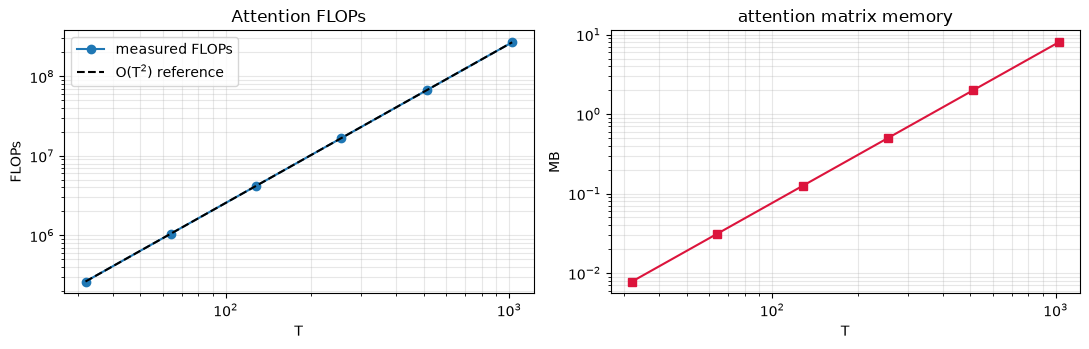

In [7]:
d_k = d_v = 64
Ts = [32, 64, 128, 256, 512, 1024]
rows = []
for T in Ts:
    Q = RNG.normal(size=(T, d_k)); K = RNG.normal(size=(T, d_k)); Vm = RNG.normal(size=(T, d_v))
    t0 = time.perf_counter()
    out, A = attention(Q, K, Vm, causal=True)
    dt = time.perf_counter() - t0
    rows.append((T, attention_flops(T, d_k, d_v), A.nbytes / 1024**2, dt))

print(f"{'T':>6} {'FLOPs':>14} {'A 메모리(MB)':>14} {'실행시간(ms)':>14} {'시간비':>8}")
prev = None
for T, f, mem, dt in rows:
    ratio = "-" if prev is None else f"{dt/prev:.2f}x"
    print(f"{T:>6} {f:>14,} {mem:>14.2f} {dt*1000:>14.2f} {ratio:>8}")
    prev = dt

print("\n→ T 를 2배로 늘리면 FLOPs 와 메모리는 약 4배(=2²)로 증가합니다.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].loglog(Ts, [r[1] for r in rows], "o-", label="measured FLOPs")
ax[0].loglog(Ts, [rows[0][1] * (t / Ts[0])**2 for t in Ts], "k--", label="O(T$^2$) reference")
ax[0].set_xlabel("T"); ax[0].set_ylabel("FLOPs"); ax[0].legend(); ax[0].set_title("Attention FLOPs")
ax[1].loglog(Ts, [r[2] for r in rows], "s-", color="crimson")
ax[1].set_xlabel("T"); ax[1].set_ylabel("MB"); ax[1].set_title("attention matrix memory")
for a in ax: a.grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

### 2-3. 📝 서술형
GPT-4 Turbo는 입력 토큰이 8,192 → **128,000** 으로 늘어났습니다 (강의자료 "GPT-4 Turbo의 성능 개선").
어텐션 행렬만 FP16으로 저장한다고 할 때 필요한 메모리를 계산하고, 왜 트랜스포머 대안(문제 5, 6)이
연구되는지 2~3문장으로 설명하세요.


In [8]:
# 2-3 계산 근거
for T in [8_192, 128_000]:
    mem = T * T * 2 / 1024**3          # FP16 = 2 bytes
    print(f"T={T:>7,}  어텐션 행렬 1개(헤드 1개) = {mem:10.2f} GiB")
print("\n→ 128K 컨텍스트에서는 헤드 하나의 어텐션 행렬만으로도 30GB 를 넘어",
      "\n  단순 구현으로는 GPU 메모리에 올릴 수 없습니다.")

T=  8,192  어텐션 행렬 1개(헤드 1개) =       0.12 GiB
T=128,000  어텐션 행렬 1개(헤드 1개) =      30.52 GiB

→ 128K 컨텍스트에서는 헤드 하나의 어텐션 행렬만으로도 30GB 를 넘어 
  단순 구현으로는 GPU 메모리에 올릴 수 없습니다.


In [9]:
print('FP16で8192²×2 bytesは0.125 GiB、128000²×2 bytesは約30.52 GiBで、'
      '1ヘッド・1層の行列だけでも約244倍になる。'
      '通常のattentionの計算量もO(T²)なので、長文のために線形attentionや固定状態のRetNetが研究される。'
      'FlashAttentionのような実装ではT×T行列全体の保存を避けられるが、標準attentionの理論計算量は二次のままである。')

FP16で8192²×2 bytesは0.125 GiB、128000²×2 bytesは約30.52 GiBで、1ヘッド・1層の行列だけでも約244倍になる。通常のattentionの計算量もO(T²)なので、長文のために線形attentionや固定状態のRetNetが研究される。FlashAttentionのような実装ではT×T行列全体の保存を避けられるが、標準attentionの理論計算量は二次のままである。


In [10]:
# --- 채점 2 ---
T_, dk_, dv_ = 12, 8, 5
Q_ = RNG.normal(size=(T_, dk_)); K_ = RNG.normal(size=(T_, dk_)); V_ = RNG.normal(size=(T_, dv_))
out_, A_ = attention(Q_, K_, V_, causal=True)

check("2-1 출력 shape", out_.shape == (T_, dv_) and A_.shape == (T_, T_))
check("2-1 어텐션 행 합 = 1", np.allclose(A_.sum(axis=1), 1.0))
check("2-1 causal 마스크(미래 참조 0)", np.allclose(np.triu(A_, k=1), 0.0))
check("2-1 첫 토큰은 자기 자신만 참조", abs(A_[0, 0] - 1.0) < 1e-9)

out_nc, A_nc = attention(Q_, K_, V_, causal=False)
check("2-1 non-causal 은 마스킹 없음", not np.allclose(np.triu(A_nc, k=1), 0.0))
check("2-1 스케일링 1/sqrt(d_k) 적용",
      np.allclose(A_nc, softmax(Q_ @ K_.T / np.sqrt(dk_), axis=-1)))
check("2-1 FLOPs 는 T^2 비례",
      attention_flops(2 * T_, dk_, dv_) == 4 * attention_flops(T_, dk_, dv_))
report()

[통과] 2-1 출력 shape
[통과] 2-1 어텐션 행 합 = 1
[통과] 2-1 causal 마스크(미래 참조 0)
[통과] 2-1 첫 토큰은 자기 자신만 참조
[통과] 2-1 non-causal 은 마스킹 없음
[통과] 2-1 스케일링 1/sqrt(d_k) 적용
[통과] 2-1 FLOPs 는 T^2 비례
채점 결과: 15 / 15 통과


---
# 문제 3. 정밀도 표현과 4비트 양자화
**(강의자료: "모델 경량화의 기본적 접근" — 정밀도의 표현 / 양자화 및 미세조정)**

> 모델 경량화의 가장 기본적인 접근은 학습 가능한 모수를 컴퓨터로 표현하는 **정밀도를 낮추는** 접근.
> 양자화는 학습 가능한 모수를 **고정된 수로 표현**하여 비용을 절감.

### 3-1. 단정밀도(FP32) 비트 분해
IEEE 754 단정밀도는 **부호 1bit + 지수 8bit + 가수 23bit = 32bit** 입니다.
정규화 수의 값은
$$(-1)^{s}\times 2^{(E-127)}\times\left(1+\frac{M}{2^{23}}\right)$$
NVIDIA GPU의 TF32는 여기서 가수만 10bit로 줄인 **19bit** 표현입니다.


In [11]:
def fp32_bits(x):
    s = format(int(np.float32(x).view(np.uint32)), '032b')
    return s[:1], s[1:9], s[9:]
def bits_to_float(sign, exp, mant):
    s, e, m = int(sign, 2), int(exp, 2), int(mant, 2)
    if e == 255:
        return float('nan') if m else (-1.)**s*float('inf')
    if e == 0:
        return (-1.)**s*2.**(-126)*(m/2.**23)
    return (-1.)**s*2.**(e-127)*(1+m/2.**23)
def model_memory_gb(n_params, bits):
    return n_params*bits/8/1e9

In [12]:
for x in [1., -2.5, .15625]:
    s,e,m = fp32_bits(x)
    print(x, s, e, m, '복원:', bits_to_float(s,e,m))
print('70B weights only; quantization metadata/activations/optimizer 제외')
base = model_memory_gb(70e9, 32)
for name, storage_bits in [('FP32',32), ('TF32 compute (FP32 storage)',32),
    ('FP16',16), ('BF16',16), ('INT8',8), ('INT4',4)]:
    mem = model_memory_gb(70e9, storage_bits)
    print(f'{name:<36} storage={storage_bits:2} bits | {mem:6.1f} GB | {base/mem:.1f}x')
print('TF32의 부호+지수+가수=19bit는 연산 정밀도 설명이며 저장량 19bit를 뜻하지 않는다.')

1.0 0 01111111 00000000000000000000000 복원: 1.0
-2.5 1 10000000 01000000000000000000000 복원: -2.5
0.15625 0 01111100 01000000000000000000000 복원: 0.15625
70B weights only; quantization metadata/activations/optimizer 제외
FP32                                 storage=32 bits |  280.0 GB | 1.0x
TF32 compute (FP32 storage)          storage=32 bits |  280.0 GB | 1.0x
FP16                                 storage=16 bits |  140.0 GB | 2.0x
BF16                                 storage=16 bits |  140.0 GB | 2.0x
INT8                                 storage= 8 bits |   70.0 GB | 4.0x
INT4                                 storage= 4 bits |   35.0 GB | 8.0x
TF32의 부호+지수+가수=19bit는 연산 정밀도 설명이며 저장량 19bit를 뜻하지 않는다.


### 3-2. 군집 기반 4비트 양자화와 미세조정
강의자료의 **[가중치를 4비트(4개)로 표현한 경우 양자화 및 미세조정 과정]** 을 그대로 구현합니다.

1. **군집(clustering)**: 4×4 가중치 행렬의 값들을 4개 군집으로 묶고, 각 가중치를 **군집 인덱스**로 대체
2. **군집 중심값(centroid)** 테이블만 실수로 저장 → 실제 저장 비용은 인덱스 2bit + 작은 테이블
3. **미세조정**: 변화도(gradient)를 **군집별로 합산**하여 중심값만 갱신


In [13]:
def kmeans_1d(w, n_clusters=4, n_iter=100):
    x = np.asarray(w, dtype=np.float64).reshape(-1)
    if not len(x) or not 1 <= n_clusters <= len(x) or n_iter < 1:
        raise ValueError('invalid k-means dimensions/iterations')
    c = np.linspace(x.min(), x.max(), n_clusters)
    def assign(centers):
        # n*kの巨大な距離行列を避け、分割して最近傍を探す。
        labels = np.empty(len(x), dtype=np.int64)
        for start in range(0, len(x), 4096):
            block = x[start:start+4096]
            labels[start:start+len(block)] = np.abs(block[:,None]-centers[None,:]).argmin(1)
        return labels
    for _ in range(n_iter):
        idx = assign(c)
        counts = np.bincount(idx, minlength=n_clusters)
        sums = np.bincount(idx, weights=x, minlength=n_clusters)
        new = np.divide(sums, counts, out=c.copy(), where=counts>0)
        if np.allclose(c, new, rtol=0, atol=1e-12):
            c = new; break
        c = new
    idx = assign(c)
    order = np.argsort(c)
    remap = np.empty_like(order); remap[order] = np.arange(n_clusters)
    return remap[idx].reshape(np.shape(w)), c[order]
def dequantize(idx, centroids):
    return np.asarray(centroids)[idx]
def finetune_centroids(centroids, idx, grad, lr):
    sums = np.bincount(np.asarray(idx).ravel(), weights=np.asarray(grad).ravel(), minlength=len(centroids))
    return np.asarray(centroids)-lr*sums
def compression_ratio(n_weights, n_clusters, orig_bits=32, centroid_bits=32):
    if n_weights <= 0 or n_clusters < 1:
        raise ValueError('invalid count')
    index_bits = math.ceil(math.log2(n_clusters))
    return n_weights*orig_bits/(n_weights*index_bits+n_clusters*centroid_bits)
print('4개 군집은 2bit 인덱스이다. 진짜 4bit 양자화는 16개 군집으로도 비교한다.')

4개 군집은 2bit 인덱스이다. 진짜 4bit 양자화는 16개 군집으로도 비교한다.


In [14]:
# 강의자료의 4x4 가중치 행렬 (32비트 단정밀도)
W = np.array([[ 2.09, -0.98,  1.48,  0.09],
              [ 0.05, -0.14, -1.08,  2.12],
              [-0.91,  1.92,  0.00, -1.03],
              [ 1.87,  0.00,  1.53,  1.49]])

# 강의자료의 변화도(가중치의 갱신 양)
G = np.array([[-0.03, -0.01,  0.03,  0.02],
              [-0.01,  0.01, -0.02,  0.12],
              [-0.01,  0.02,  0.04,  0.01],
              [-0.07, -0.02,  0.01, -0.02]])

idx, cent = kmeans_1d(W, n_clusters=4)
print("군집 인덱스 (2비트로 저장 가능):\n", idx)
print("\n군집 중심값:", cent)
print("\n복원된 가중치:\n", dequantize(idx, cent))
print(f"\n양자화 오차 (MSE) = {np.mean((W - dequantize(idx, cent))**2):.6f}")
print(f"압축률(16개 가중치 기준) = {compression_ratio(16, 4):.2f}x")
print(f"압축률(70억 개 가중치 기준) = {compression_ratio(7e9, 4):.2f}x   <- 테이블 비용이 무시됨")

new_cent = finetune_centroids(cent, idx, G, lr=0.05)
print("\n[미세조정] 군집별 변화도 합:")
for k in range(4):
    print(f"  군집 {k}: 합 {G[idx == k].sum():+.4f}   중심값 {cent[k]:+.4f} -> {new_cent[k]:+.4f}")

군집 인덱스 (2비트로 저장 가능):
 [[3 0 2 1]
 [1 1 0 3]
 [0 3 1 0]
 [3 1 2 2]]

군집 중심값: [-1.   0.   1.5  2. ]

복원된 가중치:
 [[ 2.  -1.   1.5  0. ]
 [ 0.   0.  -1.   2. ]
 [-1.   2.   0.  -1. ]
 [ 2.   0.   1.5  1.5]]

양자화 오차 (MSE) = 0.005825
압축률(16개 가중치 기준) = 3.20x
압축률(70억 개 가중치 기준) = 16.00x   <- 테이블 비용이 무시됨

[미세조정] 군집별 변화도 합:
  군집 0: 합 -0.0300   중심값 -1.0000 -> -0.9985
  군집 1: 합 +0.0400   중심값 +0.0000 -> -0.0020
  군집 2: 합 +0.0200   중심값 +1.5000 -> +1.4990
  군집 3: 합 +0.0400   중심값 +2.0000 -> +1.9980


### 3-3. 군집 수와 정확도-압축률 트레이드오프

   군집수      비트/가중치       압축률       가중치 MSE         출력 상대오차
     2           1     32.0x      0.363273         60.08%
     4           2     16.0x      0.118202         34.73%
     8           3     10.7x      0.035246         18.89%
    16           4      8.0x      0.012425         11.24%
    64           6      5.3x      0.001592          4.04%
   256           8      3.9x      0.000104          1.02%


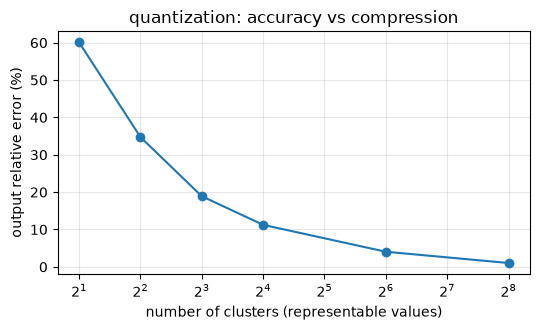

In [15]:
Wbig = RNG.normal(size=(256, 256))
x = RNG.normal(size=(64, 256))
y_ref = x @ Wbig

print(f"{'군집수':>6}{'비트/가중치':>12}{'압축률':>10}{'가중치 MSE':>14}{'출력 상대오차':>16}")
res = []
for k in [2, 4, 8, 16, 64, 256]:
    i_, c_ = kmeans_1d(Wbig, n_clusters=k, n_iter=30)
    Wq = dequantize(i_, c_)
    err = np.linalg.norm(x @ Wq - y_ref) / np.linalg.norm(y_ref)
    res.append((k, err))
    print(f"{k:>6}{math.ceil(math.log2(k)):>12}{compression_ratio(Wbig.size, k):>9.1f}x"
          f"{np.mean((Wbig-Wq)**2):>14.6f}{err:>15.2%}")

plt.figure(figsize=(5.5, 3.4))
plt.semilogx([r[0] for r in res], [r[1]*100 for r in res], "o-", base=2)
plt.xlabel("number of clusters (representable values)"); plt.ylabel("output relative error (%)")
plt.title("quantization: accuracy vs compression"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [16]:
# --- 채점 3 ---
check("3-1 FP32 비트 분해 (1.0)", fp32_bits(1.0) == ("0", "01111111", "0"*23))
check("3-1 비트→실수 복원", all(abs(bits_to_float(*fp32_bits(v)) - v) < 1e-6
                              for v in [1.0, -2.5, 0.15625, 3.75]))
check("3-1 FP32 메모리(70억)", abs(model_memory_gb(70e9, 32) - 280.0) < 1e-6)
check("3-1 INT4 는 FP32 의 1/8", abs(model_memory_gb(1e9, 4)*8 - model_memory_gb(1e9, 32)) < 1e-9)

check("3-2 인덱스 shape/범위", idx.shape == W.shape and idx.min() >= 0 and idx.max() <= 3)
check("3-2 중심값 개수 4개", len(cent) == 4)
check("3-2 중심값 = 군집 평균",
      all(abs(cent[k] - W[idx == k].mean()) < 1e-9 for k in range(4) if np.any(idx == k)))
check("3-2 양자화 오차가 충분히 작음", np.mean((W - dequantize(idx, cent))**2) < 0.05)
check("3-2 미세조정은 중심값만 갱신", new_cent.shape == cent.shape and not np.allclose(new_cent, cent))
check("3-2 압축률 계산 (1e6개, 4군집 ≈ 16x)", abs(compression_ratio(1e6, 4) - 16.0) < 0.01)
check("3-3 군집수↑ ⇒ 오차↓", all(res[i][1] >= res[i+1][1] - 1e-9 for i in range(len(res)-1)))
report()

[통과] 3-1 FP32 비트 분해 (1.0)
[통과] 3-1 비트→실수 복원
[통과] 3-1 FP32 메모리(70억)
[통과] 3-1 INT4 는 FP32 의 1/8
[통과] 3-2 인덱스 shape/범위
[통과] 3-2 중심값 개수 4개
[통과] 3-2 중심값 = 군집 평균
[통과] 3-2 양자화 오차가 충분히 작음
[통과] 3-2 미세조정은 중심값만 갱신
[통과] 3-2 압축률 계산 (1e6개, 4군집 ≈ 16x)
[통과] 3-3 군집수↑ ⇒ 오차↓
채점 결과: 26 / 26 통과


---
# 문제 4. 가지치기(Pruning)와 지식 증류(Knowledge Distillation)
**(강의자료: "가지치기와 양자화" / "지식 증류와 모수 공유 기법")**

> 지식 증류: 학생 모델을 학습할 때 **선생님 모델의 출력을 학습**하여 지식을 전이시킨다.
> 이 출력 값에 지식이 녹아 있음. (고양이 0.7 / 강아지 0.2 / 새 0.05 …)

### 4-1. 크기 기반 가지치기 (Magnitude Pruning)
절댓값이 작은 하위 $p$% 가중치를 0으로 만들고, 출력이 얼마나 망가지는지 봅니다.


In [17]:
def magnitude_prune(W, sparsity):
    if not 0 <= sparsity <= 1:
        raise ValueError('sparsity must be in [0,1]')
    n_prune = int(round(sparsity*W.size))
    mask = np.ones(W.size, dtype=bool)
    # 동률이 있어도 요청한 개수만 제거. 남은 원소는 원본 값을 유지.
    order = np.argsort(np.abs(W).ravel(), kind='stable')
    mask[order[:n_prune]] = False
    mask = mask.reshape(W.shape)
    return np.where(mask, W, 0), mask

     가지치기 비율      실제 희소도         출력 상대오차
         0%        0.0%          0.00%
        30%       30.0%         12.03%
        50%       50.0%         26.61%
        70%       70.0%         46.32%
        80%       80.0%         58.93%
        90%       90.0%         74.82%
        95%       95.0%         84.71%
        99%       99.0%         95.48%


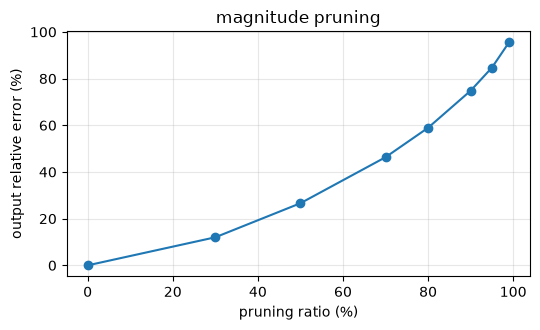

In [18]:
Wl = RNG.normal(size=(512, 512))
xin = RNG.normal(size=(128, 512))
y0 = xin @ Wl

print(f"{'가지치기 비율':>12}{'실제 희소도':>12}{'출력 상대오차':>16}")
sp_list, err_list = [], []
for sp in [0.0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]:
    Wp, m = magnitude_prune(Wl, sp)
    e = np.linalg.norm(xin @ Wp - y0) / np.linalg.norm(y0)
    sp_list.append(sp); err_list.append(e)
    print(f"{sp:>11.0%}{1 - m.mean():>12.1%}{e:>15.2%}")

plt.figure(figsize=(5.5, 3.4))
plt.plot(np.array(sp_list)*100, np.array(err_list)*100, "o-")
plt.xlabel("pruning ratio (%)"); plt.ylabel("output relative error (%)")
plt.title("magnitude pruning"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### 4-2. 지식 증류

선생님의 **soft target** 은 정답 하나(hard label)보다 훨씬 많은 정보를 담습니다
("고양이 0.7, 강아지 0.2" 는 *고양이와 강아지가 닮았다* 는 지식까지 전달).

$$\mathcal{L} = \alpha\,T^2\,\mathrm{KL}\!\left(p_T^{(\tau=T)} \,\|\, p_S^{(\tau=T)}\right)
+ (1-\alpha)\,\mathrm{CE}(p_S, y)$$

온도 $T$ 로 나눈 분포를 쓰기 때문에 기울기 크기를 보정하려고 $T^2$ 을 곱합니다.


In [19]:
def kd_loss_and_grad(student_logits, teacher_logits, y_true, T=3., alpha=.7):
    if T <= 0 or not 0 <= alpha <= 1:
        raise ValueError('T>0 and 0<=alpha<=1 required')
    N = len(y_true)
    def log_softmax(z):
        z = np.asarray(z, dtype=float)
        shifted = z-z.max(axis=-1, keepdims=True)
        return shifted-np.log(np.exp(shifted).sum(axis=-1, keepdims=True))
    lt, ls = log_softmax(teacher_logits/T), log_softmax(student_logits/T)
    lh = log_softmax(student_logits)
    pt, ps, ph = np.exp(lt), np.exp(ls), np.exp(lh)
    kl = float(np.sum(pt*(lt-ls), axis=1).mean())
    ce = float(-lh[np.arange(N), y_true].mean())
    oh = np.zeros_like(ph); oh[np.arange(N), y_true] = 1
    grad = (alpha*T*(ps-pt)+(1-alpha)*(ph-oh))/N
    return alpha*T*T*kl+(1-alpha)*ce, kl, ce, grad

In [20]:
# ---- 실험 세팅: 선생님(대량 데이터로 학습) → 학생(소량 데이터만 사용) ----
D, Cc = 20, 5
W_true = RNG.normal(size=(D, Cc)) * 1.5

def make(n):
    X = RNG.normal(size=(n, D))
    return X, np.argmax(X @ W_true + 0.5 * RNG.normal(size=(n, Cc)), axis=1)

X_tea, y_tea = make(6000)      # 선생님이 쓰는 대량 데이터
X_stu, y_stu = make(60)        # 학생이 쓰는 소량 데이터
X_te,  y_te  = make(3000)      # 평가용

def train(X, y, steps=1500, lr=.4, teacher_logits=None, T=3., alpha=.7, seed=0):
    r = np.random.default_rng(seed)
    W = torch.tensor(r.normal(size=(X.shape[1], Cc))*.01, device=DEVICE, dtype=torch.float64)
    xt = torch.tensor(X, device=DEVICE, dtype=torch.float64)
    yt = torch.tensor(y, device=DEVICE, dtype=torch.long)
    oh = torch.nn.functional.one_hot(yt, Cc).to(torch.float64)
    target_soft = None if teacher_logits is None else torch.softmax(
        torch.tensor(teacher_logits, device=DEVICE, dtype=torch.float64)/T, dim=-1)
    with torch.no_grad():
        for _ in range(steps):
            logits = xt @ W
            ph = torch.softmax(logits, dim=-1)
            if target_soft is None:
                g = (ph-oh)/len(y)
            else:
                ps = torch.softmax(logits/T, dim=-1)
                g = (alpha*T*(ps-target_soft)+(1-alpha)*(ph-oh))/len(y)
            W -= lr*(xt.T @ g)
    return W.cpu().numpy()

acc = lambda W, X, y: float((np.argmax(X @ W, axis=1) == y).mean())

W_teacher = train(X_tea, y_tea, steps=3000, lr=0.5)
teacher_logits_on_stu = X_stu @ W_teacher

W_hard = train(X_stu, y_stu)
W_kd   = train(X_stu, y_stu, teacher_logits=teacher_logits_on_stu, T=3.0, alpha=0.9)

print(f"선생님 모델 (6000개 학습)        : 테스트 정확도 {acc(W_teacher, X_te, y_te):.3f}")
print(f"학생 - hard label 만 (60개 학습) : 테스트 정확도 {acc(W_hard, X_te, y_te):.3f}")
print(f"학생 - 지식 증류    (60개 학습)  : 테스트 정확도 {acc(W_kd,   X_te, y_te):.3f}")
print("\n→ 같은 데이터·같은 크기의 학생인데도, 선생님의 '확률 분포'를 함께 배우면 성능이 올라갑니다.")

print("\n[온도 T 에 따른 선생님 분포의 평탄화]")
tl = teacher_logits_on_stu[0]
for T in [1.0, 2.0, 5.0, 10.0]:
    pt = softmax(tl / T)
    print(f"  T={T:<5} 최대확률 {pt.max():.3f}  엔트로피 {-np.sum(pt*np.log(pt+1e-12)):.3f}  {np.round(pt,3)}")

선생님 모델 (6000개 학습)        : 테스트 정확도 0.958
학생 - hard label 만 (60개 학습) : 테스트 정확도 0.627
학생 - 지식 증류    (60개 학습)  : 테스트 정확도 0.947

→ 같은 데이터·같은 크기의 학생인데도, 선생님의 '확률 분포'를 함께 배우면 성능이 올라갑니다.

[온도 T 에 따른 선생님 분포의 평탄화]
  T=1.0   최대확률 0.887  엔트로피 0.353  [0.    0.    0.    0.113 0.887]
  T=2.0   최대확률 0.734  엔트로피 0.604  [0.    0.    0.005 0.262 0.734]
  T=5.0   최대확률 0.545  엔트로피 0.990  [0.015 0.008 0.071 0.361 0.545]
  T=10.0  최대확률 0.406  엔트로피 1.344  [0.068 0.049 0.147 0.33  0.406]


In [21]:
# --- 채점 4 ---
Wp5, m5 = magnitude_prune(Wl, 0.5)
check("4-1 희소도 ≈ 50%", abs((Wp5 == 0).mean() - 0.5) < 0.02)
check("4-1 남은 가중치는 원본 그대로", np.allclose(Wp5[m5], Wl[m5]))
check("4-1 잘린 값이 남은 값보다 작음", np.abs(Wl[~m5]).max() <= np.abs(Wl[m5]).min() + 1e-12)
check("4-1 가지치기↑ ⇒ 오차↑", all(err_list[i] <= err_list[i+1] + 1e-9 for i in range(len(err_list)-1)))

sl = RNG.normal(size=(8, Cc)); tlg = RNG.normal(size=(8, Cc)); yy = RNG.integers(0, Cc, 8)
L, kl, ce, g = kd_loss_and_grad(sl, tlg, yy, T=3.0, alpha=0.7)
check("4-2 KL >= 0", kl >= -1e-12)
check("4-2 학생=선생님 이면 KL=0", abs(kd_loss_and_grad(tlg, tlg, yy)[1]) < 1e-9)
check("4-2 grad shape", g.shape == sl.shape)

# 수치 미분으로 기울기 검증
eps, i0, j0 = 1e-6, 3, 2
sp_, sm_ = sl.copy(), sl.copy(); sp_[i0, j0] += eps; sm_[i0, j0] -= eps
num = (kd_loss_and_grad(sp_, tlg, yy, 3.0, 0.7)[0] - kd_loss_and_grad(sm_, tlg, yy, 3.0, 0.7)[0]) / (2*eps)
check("4-2 해석적 기울기 = 수치 기울기", abs(num - g[i0, j0]) < 1e-6, f"{num:.8f} vs {g[i0,j0]:.8f}")
check("4-2 지식 증류가 hard label 보다 우수",
      acc(W_kd, X_te, y_te) > acc(W_hard, X_te, y_te))
check("4-2 온도↑ ⇒ 분포 평탄화",
      softmax(tl/10).max() < softmax(tl/1).max())
report()

[통과] 4-1 희소도 ≈ 50%
[통과] 4-1 남은 가중치는 원본 그대로
[통과] 4-1 잘린 값이 남은 값보다 작음
[통과] 4-1 가지치기↑ ⇒ 오차↑
[통과] 4-2 KL >= 0
[통과] 4-2 학생=선생님 이면 KL=0
[통과] 4-2 grad shape
[통과] 4-2 해석적 기울기 = 수치 기울기
[통과] 4-2 지식 증류가 hard label 보다 우수
[통과] 4-2 온도↑ ⇒ 분포 평탄화
채점 결과: 36 / 36 통과


---
# 문제 5. 선형 트랜스포머 — 커널 함수로 softmax 근사
**(강의자료: "트랜스포머 대안의 기본적 접근" — 선형 트랜스포머)**

> 선형 트랜스포머는 softmax로 얻을 수 있는 **비선형성을 커널 함수로 선형화**하여 계산의 이점을 확보하는 구조.
> $$A = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V \;\;\approx\;\; \phi(Q)\,\phi(K)^\top V$$

**핵심은 결합법칙입니다.**

| | 계산 순서 | 복잡도 |
|---|---|---|
| 일반 어텐션 | $\big(QK^\top\big)V$ — T×T 행렬을 **반드시 만들어야** 함 | $O(T^2 d)$ |
| 선형 어텐션 | $\phi(Q)\big(\phi(K)^\top V\big)$ — d×d 행렬만 만들면 됨 | $O(T d^2)$ |

softmax는 $\exp$ 때문에 분해가 불가능하지만, 커널 $\phi$ 를 쓰면 순서를 바꿀 수 있습니다.
여기서는 $\phi(x)=\mathrm{elu}(x)+1$ (항상 양수) 를 사용합니다.


In [22]:
def phi(x):
    x = np.asarray(x, dtype=float)
    return np.where(x>0, x+1, np.exp(np.clip(x, -700, 0)))
def linear_attention(Q, K, Vm):
    Qp, Kp = phi(Q), phi(K)
    KV = Kp.T @ Vm
    Z = Qp @ Kp.sum(axis=0)
    return (Qp @ KV)/np.maximum(Z[:,None], np.finfo(float).tiny)
def linear_attention_flops(T, d_k, d_v):
    return 4*T*d_k*d_v

      T     softmax FLOPs    linear FLOPs      절감배수  softmax(ms)  linear(ms)      속도향상
     64         1,048,576       1,048,576      1.0x         0.11        0.13      0.9x
    128         4,194,304       2,097,152      2.0x         0.30        0.24      1.3x
    256        16,777,216       4,194,304      4.0x         0.45        0.37      1.2x
    512        67,108,864       8,388,608      8.0x         3.02        0.58      5.2x
   1024       268,435,456      16,777,216     16.0x        10.43        1.29      8.1x
   2048     1,073,741,824      33,554,432     32.0x        45.80        3.60     12.7x


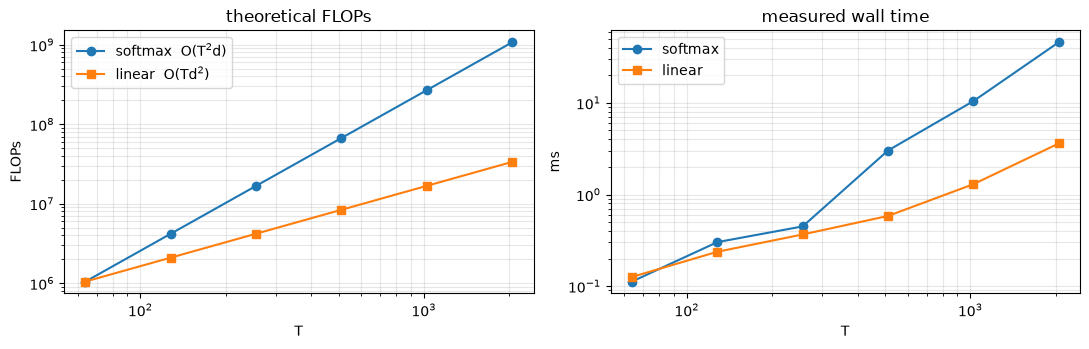

In [23]:
d = 64
print(f"{'T':>7}{'softmax FLOPs':>18}{'linear FLOPs':>16}{'절감배수':>10}"
      f"{'softmax(ms)':>13}{'linear(ms)':>12}{'속도향상':>10}")
Ts = [64, 128, 256, 512, 1024, 2048]
f_soft, f_lin, t_soft, t_lin = [], [], [], []
for T in Ts:
    Q = RNG.normal(size=(T, d)); K = RNG.normal(size=(T, d)); Vm = RNG.normal(size=(T, d))
    fs, fl = attention_flops(T, d, d), linear_attention_flops(T, d, d)

    t0 = time.perf_counter(); attention(Q, K, Vm); ts = time.perf_counter() - t0
    t0 = time.perf_counter(); linear_attention(Q, K, Vm); tl_ = time.perf_counter() - t0

    f_soft.append(fs); f_lin.append(fl); t_soft.append(ts); t_lin.append(tl_)
    print(f"{T:>7}{fs:>18,}{fl:>16,}{fs/fl:>9.1f}x{ts*1000:>13.2f}{tl_*1000:>12.2f}{ts/tl_:>9.1f}x")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].loglog(Ts, f_soft, "o-", label="softmax  O(T$^2$d)")
ax[0].loglog(Ts, f_lin, "s-", label="linear  O(Td$^2$)")
ax[0].set_xlabel("T"); ax[0].set_ylabel("FLOPs"); ax[0].legend(); ax[0].set_title("theoretical FLOPs")
ax[1].loglog(Ts, np.array(t_soft)*1000, "o-", label="softmax")
ax[1].loglog(Ts, np.array(t_lin)*1000, "s-", label="linear")
ax[1].set_xlabel("T"); ax[1].set_ylabel("ms"); ax[1].legend(); ax[1].set_title("measured wall time")
for a in ax: a.grid(alpha=.3, which="both")
plt.tight_layout(); plt.show()

### 5-2. 근사 품질 확인
선형 어텐션은 **정확한 재현이 아니라 근사**입니다. 얼마나 비슷한지 봅시다.


In [24]:
T = 256
Q = RNG.normal(size=(T, d)) * 0.5; K = RNG.normal(size=(T, d)) * 0.5; Vm = RNG.normal(size=(T, d))
o_soft, _ = attention(Q, K, Vm)
o_lin = linear_attention(Q, K, Vm)

cos = np.sum(o_soft*o_lin, axis=1) / (np.linalg.norm(o_soft, axis=1)*np.linalg.norm(o_lin, axis=1))
print(f"출력 상대오차   = {np.linalg.norm(o_soft-o_lin)/np.linalg.norm(o_soft):.2%}")
print(f"행별 코사인유사도 평균 = {cos.mean():.4f}")
print("\n→ 완전히 같지는 않지만 방향성은 상당 부분 보존됩니다.")
print("   이것이 강의자료의 '적은 계산량으로 어텐션을 근사' 라는 표현의 의미입니다.")

출력 상대오차   = 21.18%
행별 코사인유사도 평균 = 0.9776

→ 완전히 같지는 않지만 방향성은 상당 부분 보존됩니다.
   이것이 강의자료의 '적은 계산량으로 어텐션을 근사' 라는 표현의 의미입니다.


In [25]:
# --- 채점 5 ---
check("5 phi 는 항상 양수", (phi(RNG.normal(size=2000)) > 0).all())
check("5 phi(x)=x+1 (x>0)", np.allclose(phi(np.array([0.5, 2.0])), np.array([1.5, 3.0])))
check("5 phi(x)=exp(x) (x<=0)", np.allclose(phi(np.array([-1.0, -2.0])), np.exp([-1.0, -2.0])))

Qs, Ks, Vs = RNG.normal(size=(30, 8)), RNG.normal(size=(30, 8)), RNG.normal(size=(30, 6))
check("5 출력 shape", linear_attention(Qs, Ks, Vs).shape == (30, 6))

# 결합법칙 검증: 순진하게 phi(Q)phi(K)^T 를 만든 뒤 V 를 곱한 것과 같아야 한다
Sn = phi(Qs) @ phi(Ks).T
naive = (Sn / Sn.sum(axis=1, keepdims=True)) @ Vs
check("5 결합법칙 성립 (naive 와 동일)", np.allclose(linear_attention(Qs, Ks, Vs), naive, atol=1e-8))

# 볼록결합이므로 출력은 V 의 min~max 범위 안에 있어야 한다
lo = linear_attention(Qs, Ks, Vs)
check("5 출력이 V 의 볼록결합 범위 내",
      (lo >= Vs.min(axis=0) - 1e-8).all() and (lo <= Vs.max(axis=0) + 1e-8).all())
check("5 FLOPs 가 T 에 선형",
      linear_attention_flops(2000, d, d) == 2 * linear_attention_flops(1000, d, d))
check("5 T=2048 에서 선형이 더 쌈", f_lin[-1] < f_soft[-1])
report()

[통과] 5 phi 는 항상 양수
[통과] 5 phi(x)=x+1 (x>0)
[통과] 5 phi(x)=exp(x) (x<=0)
[통과] 5 출력 shape
[통과] 5 결합법칙 성립 (naive 와 동일)
[통과] 5 출력이 V 의 볼록결합 범위 내
[통과] 5 FLOPs 가 T 에 선형
[통과] 5 T=2048 에서 선형이 더 쌈
채점 결과: 44 / 44 통과


---
# 문제 6. RetNet 리텐션 — 병렬 표현과 재귀 표현의 등가성
**(강의자료: "Retentive Network의 접근과 특징" — 불가능한 삼각형 / 리텐션 메커니즘)**

> 언어 모델을 구현하는 세 가지 방식은 각기 장단점이 뚜렷하여 **불가능한 삼각형** 구도로 해석할 수 있다.
> RetNet은 **학습 시 병렬화 · 저비용 추론 · 높은 성능**을 모두 달성할 수 있는 대안으로 제시.
>
> RetNet의 핵심은 토큰 관계를 설정하는 **하나의 수식**으로, 학습 시에 활용하는 **병렬 표현**과
> 추론 시에 활용하는 **재귀 표현**이 가능.

|  | 학습 시 병렬화 | 저비용 추론 | 높은 성능 |
|---|---|---|---|
| 트랜스포머 | ✅ | ❌ (KV 캐시가 T에 비례) | ✅ |
| 순환신경망 | ❌ | ✅ | △ |
| 선형 트랜스포머 | ✅ | ✅ | △ |
| **RetNet** | ✅ | ✅ | ✅ |

### 수식
**병렬 표현** (학습용) — 감쇠 행렬 $D$ 와 아다마르 곱:
$$O = (QK^\top \odot D)V,\qquad D_{nm}=\begin{cases}\gamma^{\,n-m} & n\ge m\\ 0 & n<m\end{cases}$$

**재귀 표현** (추론용) — 은닉 상태 $S_n \in \mathbb{R}^{d_k\times d_v}$:
$$S_n = \gamma S_{n-1} + K_n^\top V_n,\qquad o_n = Q_n S_n$$

**이 두 식이 수학적으로 완전히 동일함**을 코드로 증명하는 것이 이 문제의 목표입니다.


In [26]:
def decay_matrix(T, gamma):
    if not 0 <= gamma <= 1:
        raise ValueError('gamma must be in [0,1]')
    delta = np.arange(T)[:,None]-np.arange(T)[None,:]
    # max(delta,0)는 gamma=0에서 음수 거듭제곱 경고를 피한다. 0**0=1.
    return np.where(delta>=0, gamma**np.maximum(delta,0), 0.)
def retention_parallel(Q, K, Vm, gamma):
    return ((Q @ K.T)*decay_matrix(len(Q),gamma)) @ Vm
def retention_recurrent(Q, K, Vm, gamma):
    if not 0 <= gamma <= 1:
        raise ValueError('gamma must be in [0,1]')
    state = np.zeros((Q.shape[1], Vm.shape[1]))
    out = np.zeros((len(Q), Vm.shape[1]))
    for n in range(len(Q)):
        state = gamma*state+np.outer(K[n],Vm[n])
        out[n] = Q[n] @ state
    return out

In [27]:
T, d_k, d_v, gamma = 64, 16, 16, 0.9
Q = RNG.normal(size=(T, d_k)); K = RNG.normal(size=(T, d_k)); Vm = RNG.normal(size=(T, d_v))

o_par = retention_parallel(Q, K, Vm, gamma)
o_rec = retention_recurrent(Q, K, Vm, gamma)

print("병렬 표현 출력[:2, :4]\n", o_par[:2, :4])
print("\n재귀 표현 출력[:2, :4]\n", o_rec[:2, :4])
print(f"\n최대 절대 오차 = {np.abs(o_par - o_rec).max():.3e}   ← 수치오차 수준이면 완전히 동일")

D = decay_matrix(8, 0.9)
print("\n감쇠 행렬 D (T=8, gamma=0.9)  — 하삼각이며 과거로 갈수록 지수 감쇠:")
print(np.round(D, 3))

병렬 표현 출력[:2, :4]
 [[  1.9777   0.4081   0.1842  -1.782 ]
 [ 18.2061  -1.9919  -2.9414 -11.1724]]

재귀 표현 출력[:2, :4]
 [[  1.9777   0.4081   0.1842  -1.782 ]
 [ 18.2061  -1.9919  -2.9414 -11.1724]]

최대 절대 오차 = 1.421e-14   ← 수치오차 수준이면 완전히 동일

감쇠 행렬 D (T=8, gamma=0.9)  — 하삼각이며 과거로 갈수록 지수 감쇠:
[[1.    0.    0.    0.    0.    0.    0.    0.   ]
 [0.9   1.    0.    0.    0.    0.    0.    0.   ]
 [0.81  0.9   1.    0.    0.    0.    0.    0.   ]
 [0.729 0.81  0.9   1.    0.    0.    0.    0.   ]
 [0.656 0.729 0.81  0.9   1.    0.    0.    0.   ]
 [0.59  0.656 0.729 0.81  0.9   1.    0.    0.   ]
 [0.531 0.59  0.656 0.729 0.81  0.9   1.    0.   ]
 [0.478 0.531 0.59  0.656 0.729 0.81  0.9   1.   ]]


### 6-2. 왜 재귀 표현이 "저비용 추론"인가
트랜스포머는 토큰을 하나 생성할 때마다 과거 전체의 K, V를 저장(KV 캐시)해야 하므로
메모리가 $O(T)$ 로 자랍니다. RetNet의 재귀 표현은 **은닉 상태 $S$ 하나($d_k \times d_v$)** 만
유지하므로 시퀀스 길이와 **무관하게 $O(1)$** 입니다.


In [28]:
print(f"{'T':>8}{'KV캐시(트랜스포머, MB)':>26}{'은닉상태 S(RetNet, MB)':>26}")
for T_ in [1_000, 10_000, 100_000, 1_000_000]:
    kv = 2 * T_ * d_k * 4 / 1024**2      # K, V 각각 (T, d_k), FP32
    s  = d_k * d_v * 4 / 1024**2         # S 하나
    print(f"{T_:>8,}{kv:>26.3f}{s:>26.3f}")
print("\n→ RetNet 의 추론 메모리는 시퀀스 길이가 100만이 되어도 그대로입니다.")

# 재귀 표현의 스트리밍 추론 시연: 토큰이 하나씩 도착하는 상황
S = np.zeros((d_k, d_v)); stream = []
for n in range(T):
    S = gamma * S + np.outer(K[n], Vm[n])
    stream.append(Q[n] @ S)              # 이 시점까지의 정보만으로 출력 생성
print(f"\n스트리밍 추론 == 병렬 학습 결과 : {np.allclose(np.array(stream), o_par)}")

       T           KV캐시(트랜스포머, MB)        은닉상태 S(RetNet, MB)
   1,000                     0.122                     0.001
  10,000                     1.221                     0.001
 100,000                    12.207                     0.001
1,000,000                   122.070                     0.001

→ RetNet 의 추론 메모리는 시퀀스 길이가 100만이 되어도 그대로입니다.

스트리밍 추론 == 병렬 학습 결과 : True


### 6-3. 📝 서술형
감쇠 계수 $\gamma$ 를 0.5 / 0.9 / 0.99 로 바꿔가며 아래 셀을 실행하고,
$\gamma$ 가 **모델이 기억할 수 있는 문맥의 길이**와 어떤 관계인지 설명하세요.
또한 $\gamma=1$ 로 두면 어떤 문제가 생길지 서술하세요.


gamma=0.5   유효 문맥 길이 ≈      2.0 토큰,  가중치가 0.5 이하로 떨어지는 거리 = 2
gamma=0.9   유효 문맥 길이 ≈     10.0 토큰,  가중치가 0.5 이하로 떨어지는 거리 = 7
gamma=0.99  유효 문맥 길이 ≈     86.6 토큰,  가중치가 0.5 이하로 떨어지는 거리 = 69
gamma=1.0   유효 문맥 길이 ≈    200.0 토큰,  가중치가 0.5 이하로 떨어지는 거리 = 200


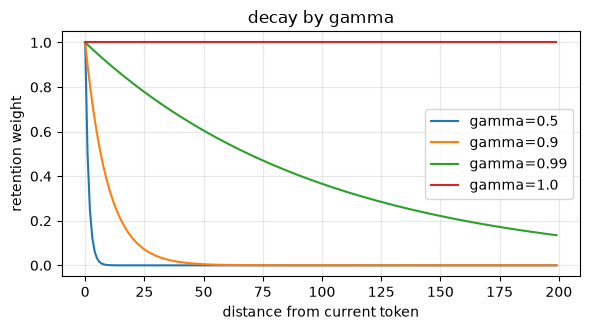

In [29]:
for g in [0.5, 0.9, 0.99, 1.0]:
    D = decay_matrix(200, g)
    w = D[-1]                                       # 마지막 토큰이 과거를 보는 가중치
    eff = np.sum(w) / (w.max() + 1e-12)             # 유효 문맥 길이 근사
    half = np.argmax(w[::-1] < 0.5) if (w < 0.5).any() else len(w)
    print(f"gamma={g:<5} 유효 문맥 길이 ≈ {eff:8.1f} 토큰,  가중치가 0.5 이하로 떨어지는 거리 = {half}")

plt.figure(figsize=(6, 3.4))
for g in [0.5, 0.9, 0.99, 1.0]:
    plt.plot(decay_matrix(200, g)[-1][::-1], label=f"gamma={g}")
plt.xlabel("distance from current token"); plt.ylabel("retention weight")
plt.title("decay by gamma"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [30]:
print('gamma=0.5/0.9/0.99일 때 무한 길이의 가중치 합 1/(1-gamma)는 약 2/10/100이므로 '
      'gamma가 클수록 과거 정보를 오래 유지한다. 반감 거리는 log(0.5)/log(gamma)로 약 1/6.58/68.97토큰이다. '
      'gamma=1이면 감쇠 없이 모든 외적이 누적되어 문맥 구분이 약해지고 상태 크기와 수치 범위가 커질 수 있다. '
      '고정된 크기의 상태는 메모리 이점을 주지만 과거 모든 정보를 손실 없이 기억한다는 뜻은 아니다.')

gamma=0.5/0.9/0.99일 때 무한 길이의 가중치 합 1/(1-gamma)는 약 2/10/100이므로 gamma가 클수록 과거 정보를 오래 유지한다. 반감 거리는 log(0.5)/log(gamma)로 약 1/6.58/68.97토큰이다. gamma=1이면 감쇠 없이 모든 외적이 누적되어 문맥 구분이 약해지고 상태 크기와 수치 범위가 커질 수 있다. 고정된 크기의 상태는 메모리 이점을 주지만 과거 모든 정보를 손실 없이 기억한다는 뜻은 아니다.


In [31]:
# --- 채점 6 ---
check("6-a D 는 하삼각", np.allclose(np.triu(decay_matrix(10, 0.9), k=1), 0.0))
check("6-a D 대각 = 1", np.allclose(np.diag(decay_matrix(10, 0.9)), 1.0))
check("6-a D[n,m] = gamma^(n-m)", abs(decay_matrix(10, 0.9)[7, 3] - 0.9**4) < 1e-12)

check("6 병렬 == 재귀 (핵심)", np.allclose(o_par, o_rec, atol=1e-8),
      f"max diff = {np.abs(o_par-o_rec).max():.2e}")

for g in [0.0, 0.5, 0.99]:
    a = retention_parallel(Q, K, Vm, g); b = retention_recurrent(Q, K, Vm, g)
    check(f"6 gamma={g} 에서도 등가", np.allclose(a, b, atol=1e-8))

check("6 인과성 (미래 참조 없음)",
      np.allclose(retention_parallel(Q[:5], K[:5], Vm[:5], gamma), o_par[:5], atol=1e-8))
check("6 gamma=0 이면 자기 자신만",
      np.allclose(retention_parallel(Q, K, Vm, 0.0),
                  (np.sum(Q*K, axis=1)[:, None]) * Vm, atol=1e-8))
report()

[통과] 6-a D 는 하삼각
[통과] 6-a D 대각 = 1
[통과] 6-a D[n,m] = gamma^(n-m)
[통과] 6 병렬 == 재귀 (핵심)
[통과] 6 gamma=0.0 에서도 등가
[통과] 6 gamma=0.5 에서도 등가
[통과] 6 gamma=0.99 에서도 등가
[통과] 6 인과성 (미래 참조 없음)
[통과] 6 gamma=0 이면 자기 자신만
채점 결과: 53 / 53 통과


---
# 문제 7. RAG(검색 증강 생성)와 환각 효과 완화
**(강의자료: "환각 효과 완화의 기본적 접근")**

> - **충실성(Faithfulness) 환각**: 생성된 내용이 **주어진 맥락과 일치하지 않는** 경우
>   (예: 2023년 4월의 기사를 요약하는데 2006년 4월로 요약)
> - **사실성(Factuality) 환각**: 생성된 내용이 **현실의 사실과 모순되는** 경우
>   (예: 세종대왕 시대의 맥북에 대하여 응답하는 경우)
>
> **검색 증강 생성(RAG)**: 사용자 프롬프트 + 쿼리 → 외부 데이터에서 증강된 정보를 찾아
> "프롬프트 + 쿼리 + 증강된 정보" 를 거대 언어 모델에 전달

### 7-1. TF-IDF 임베딩과 코사인 유사도 검색기 구현


In [32]:
KNOWLEDGE_BASE = [
    "ChatGPT는 GPT-3.5 모델을 사용하며 2022년 11월에 공개되었다.",
    "GPT-4는 OpenAI가 2023년 3월에 공개한 모델로 텍스트에 더해 이미지를 처리할 수 있다.",
    "GPT-4 Turbo의 입력 토큰은 128000개이며 학습 데이터는 2023년 12월까지이다.",
    "GPT-4의 입력 토큰은 8192개이며 학습 데이터는 2021년 9월까지이다.",
    "Gemini는 구글의 멀티 모달 인공지능이며 Bard를 리브랜딩한 이름이다.",
    "Gemini는 규모가 큰 순서대로 Ultra, Pro, Nano 버전으로 구분된다.",
    "Claude는 앤트로픽이 개발한 거대 언어 모델이며 2023년 3월에 처음 공개되었다.",
    "앤트로픽은 OpenAI에서 GPT-3를 개발한 인력이 창업한 기업이다.",
    "LLaMA는 메타가 2023년 2월에 공개한 오픈 소스 거대 언어 모델이다.",
    "LLaMA 3.1 405B의 학습 가능한 모수는 4050억 개이며 학습 데이터는 15.6조 토큰이다.",
    "Solar 10.7B는 업스테이지가 DUS 기법으로 개발한 한국의 sLLM 모델이다.",
    "sLLM의 규모는 대략 2B에서 70B 사이이며 2023년부터 본격적으로 등장했다.",
    "Mistral 7B는 프랑스의 Mistral AI가 공개한 70억 개 모수의 오픈 소스 모델이다.",
    "phi 시리즈는 마이크로소프트가 개발한 sLLM으로 교과서 수준의 합성 데이터를 활용한다.",
    "Gemma는 구글이 공개한 sLLM으로 2B와 7B 소형 모델로 구성된다.",
]

def tokenize(text):
    """한글/영문/숫자 토큰 추출 후 소문자화."""
    return re.findall(r"[가-힣]+|[a-zA-Z]+|[0-9]+", text.lower())


def build_tfidf(docs):
    toks = [tokenize(d) for d in docs]
    vocab = {w:i for i,w in enumerate(sorted({w for ts in toks for w in ts}))}
    tf = np.zeros((len(docs),len(vocab)))
    for row, ts in enumerate(toks):
        for t in ts: tf[row,vocab[t]] += 1
    df = (tf>0).sum(axis=0)
    idf = np.log((1+len(docs))/(1+df))+1
    sums = tf.sum(axis=1,keepdims=True)
    tf = np.divide(tf,sums,out=np.zeros_like(tf),where=sums>0)
    return tf*idf, vocab, idf
def embed(text, vocab, idf):
    v = np.zeros(len(vocab))
    for t in tokenize(text):
        if t in vocab: v[vocab[t]] += 1
    if v.sum(): v /= v.sum()
    return v*idf
def cosine_sim(a, B):
    norm = np.linalg.norm(a)*np.linalg.norm(B,axis=1)
    return np.clip(np.divide(B @ a,norm,out=np.zeros(len(B)),where=norm>0),-1,1)
def retrieve(query, docs, DM, vocab, idf, k=3):
    if k<0: raise ValueError('k must be nonnegative')
    scores = cosine_sim(embed(query,vocab,idf),DM)
    ids = np.argsort(-scores,kind='stable')[:min(k,len(docs))]
    return [(docs[i],float(scores[i]),int(i)) for i in ids]


def build_prompt(query, retrieved):
    """강의자료: '프롬프트 + 쿼리 + 증강된 정보' 형태로 조립."""
    ctx = "\n".join(f"[문서{i+1}] {d}" for i, (d, s, _) in enumerate(retrieved))
    return (
        "다음 참고 문서에 근거해서만 답변하시오. 문서에 없는 내용은 '모름'이라고 답하시오.\n\n"
        f"[참고 문서]\n{ctx}\n\n"
        f"[질문] {query}\n\n[답변]"
    )

In [33]:
DM, VOCAB_R, IDF = build_tfidf(KNOWLEDGE_BASE)
print(f"문서 {DM.shape[0]}개, 어휘 {DM.shape[1]}개")

for q in ["GPT-4 Turbo의 입력 토큰은 몇 개인가?",
          "한국의 sLLM 모델은?",
          "앤트로픽은 누가 만들었나?"]:
    print(f"\n■ 질의: {q}")
    for rank, (doc, s, i) in enumerate(retrieve(q, KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=3), 1):
        print(f"   {rank}. (유사도 {s:.3f}) {doc}")

print("\n" + "="*70)
print("[증강된 프롬프트 예시]")
print("="*70)
print(build_prompt("GPT-4 Turbo의 입력 토큰은 몇 개인가?",
                   retrieve("GPT-4 Turbo의 입력 토큰은 몇 개인가?", KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=2)))

문서 15개, 어휘 117개

■ 질의: GPT-4 Turbo의 입력 토큰은 몇 개인가?
   1. (유사도 0.656) GPT-4 Turbo의 입력 토큰은 128000개이며 학습 데이터는 2023년 12월까지이다.
   2. (유사도 0.504) GPT-4의 입력 토큰은 8192개이며 학습 데이터는 2021년 9월까지이다.
   3. (유사도 0.148) GPT-4는 OpenAI가 2023년 3월에 공개한 모델로 텍스트에 더해 이미지를 처리할 수 있다.

■ 질의: 한국의 sLLM 모델은?
   1. (유사도 0.411) Solar 10.7B는 업스테이지가 DUS 기법으로 개발한 한국의 sLLM 모델이다.
   2. (유사도 0.129) phi 시리즈는 마이크로소프트가 개발한 sLLM으로 교과서 수준의 합성 데이터를 활용한다.
   3. (유사도 0.124) Gemma는 구글이 공개한 sLLM으로 2B와 7B 소형 모델로 구성된다.

■ 질의: 앤트로픽은 누가 만들었나?
   1. (유사도 0.363) 앤트로픽은 OpenAI에서 GPT-3를 개발한 인력이 창업한 기업이다.
   2. (유사도 0.000) ChatGPT는 GPT-3.5 모델을 사용하며 2022년 11월에 공개되었다.
   3. (유사도 0.000) GPT-4는 OpenAI가 2023년 3월에 공개한 모델로 텍스트에 더해 이미지를 처리할 수 있다.

[증강된 프롬프트 예시]
다음 참고 문서에 근거해서만 답변하시오. 문서에 없는 내용은 '모름'이라고 답하시오.

[참고 문서]
[문서1] GPT-4 Turbo의 입력 토큰은 128000개이며 학습 데이터는 2023년 12월까지이다.
[문서2] GPT-4의 입력 토큰은 8192개이며 학습 데이터는 2021년 9월까지이다.

[질문] GPT-4 Turbo의 입력 토큰은 몇 개인가?

[답변]


### 7-2. 충실성(Faithfulness) 점수로 환각 탐지

RAG를 붙여도 모델이 맥락에 없는 말을 지어낼 수 있습니다.
**답변에 등장한 숫자·고유명사가 참고 문서 안에 실제로 존재하는지** 검사하여 충실성을 정량화합니다.


In [34]:
# 한국어는 조사가 붙어 형태가 달라지므로 간단히 어미/조사를 떼어낸다 (긴 것부터)
PARTICLES = ["이라고", "으로는", "이며는", "에게서", "이었다", "하였다",
             "이며", "이다", "에서", "으로", "까지", "에게", "라고", "부터", "처럼",
             "은", "는", "이", "가", "을", "를", "의", "에", "로", "와", "과", "도", "만", "고"]
STOPWORDS = {"", "개", "년", "월", "있다", "하다", "그리고", "및", "약", "등", "것", "몇"}


COPULA = {"이다", "이며", "이었다", "하였다"}   # 서술격 조사는 1글자만 남아도 떼어냄

def strip_particle(tok):
    """한글 토큰 끝의 조사/어미를 1회 제거."""
    for p in PARTICLES:
        min_stem = 1 if p in COPULA else 2
        if tok.endswith(p) and len(tok) - len(p) >= min_stem:
            return tok[: -len(p)]
    return tok


def content_tokens(text):
    tokens = [strip_particle(t) for t in tokenize(text)]
    return [t for t in tokens if t not in STOPWORDS]
def faithfulness_score(answer, context):
    tokens = content_tokens(answer)
    supported = set(content_tokens(context))
    return 1.0 if not tokens else sum(t in supported for t in tokens)/len(tokens)
def unsupported_tokens(answer, context):
    supported = set(content_tokens(context))
    return [t for t in content_tokens(answer) if t not in supported]

In [35]:
query = "GPT-4 Turbo의 입력 토큰은 몇 개인가?"
retr = retrieve(query, KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=1)   # 최상위 근거 문서만 맥락으로
context = " ".join(d for d, _, _ in retr)

candidates = [
    ("GPT-4 Turbo의 입력 토큰은 128000개이다.",              "정상 (맥락 근거 있음)"),
    ("GPT-4 Turbo의 입력 토큰은 8192개이다.",                "충실성 환각 (다른 문서의 수치를 혼동)"),
    ("GPT-4 Turbo의 입력 토큰은 1000000개이며 무료이다.",    "충실성 환각 (맥락에 없는 수치 생성)"),
    ("세종대왕이 GPT-4 Turbo의 맥북을 던졌다.",              "사실성 환각 (현실과 모순)"),
]

print(f"[맥락] {context}\n")
print(f"{'충실성':>8}  {'판정':<28} 답변")
print("-" * 100)
for ans, label in candidates:
    fs = faithfulness_score(ans, context)
    print(f"{fs:>7.2f}  {label:<28} {ans}")
    un = unsupported_tokens(ans, context)
    if un:
        print(f"{'':>10}근거 없는 토큰: {un}")

[맥락] GPT-4 Turbo의 입력 토큰은 128000개이며 학습 데이터는 2023년 12월까지이다.

     충실성  판정                           답변
----------------------------------------------------------------------------------------------------
   1.00  정상 (맥락 근거 있음)                GPT-4 Turbo의 입력 토큰은 128000개이다.
   0.86  충실성 환각 (다른 문서의 수치를 혼동)       GPT-4 Turbo의 입력 토큰은 8192개이다.
          근거 없는 토큰: ['8192']
   0.75  충실성 환각 (맥락에 없는 수치 생성)        GPT-4 Turbo의 입력 토큰은 1000000개이며 무료이다.
          근거 없는 토큰: ['1000000', '무료']
   0.57  사실성 환각 (현실과 모순)              세종대왕이 GPT-4 Turbo의 맥북을 던졌다.
          근거 없는 토큰: ['세종대왕', '맥북', '던졌다']


### 7-3. RAG 유무에 따른 환각 비교

질의                                        RAG 없음      RAG 사용
--------------------------------------------------------------
GPT-4 Turbo의 입력 토큰은 몇 개인가?                  0.86        1.00
LLaMA 3.1 405B의 모수는 몇 개인가?                  0.78        0.91
한국의 sLLM 모델은 무엇인가?                          0.71        0.89
--------------------------------------------------------------
평균 충실성                                      0.78        0.93


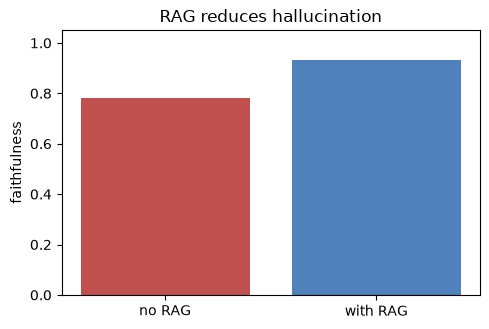

In [36]:
# RAG 없이 답하는 '모델' (학습 데이터에 의존 → 오래된/틀린 값을 말함)
NO_RAG_ANSWERS = {
    "GPT-4 Turbo의 입력 토큰은 몇 개인가?": "GPT-4 Turbo의 입력 토큰은 8192개이다.",
    "LLaMA 3.1 405B의 모수는 몇 개인가?":   "LLaMA 3.1 405B의 모수는 700억개이다.",
    "한국의 sLLM 모델은 무엇인가?":         "한국의 sLLM 모델은 Mistral 7B이다.",
}
# RAG 를 붙인 '모델' (검색된 문서를 그대로 인용)
RAG_ANSWERS = {
    "GPT-4 Turbo의 입력 토큰은 몇 개인가?": "GPT-4 Turbo의 입력 토큰은 128000개이다.",
    "LLaMA 3.1 405B의 모수는 몇 개인가?":   "LLaMA 3.1 405B의 학습 가능한 모수는 4050억개이다.",
    "한국의 sLLM 모델은 무엇인가?":         "한국의 sLLM 모델은 업스테이지의 Solar 10.7B이다.",
}

print(f"{'질의':<36}{'RAG 없음':>12}{'RAG 사용':>12}")
print("-" * 62)
no_rag, with_rag = [], []
for q in NO_RAG_ANSWERS:
    ctx = " ".join(d for d, _, _ in retrieve(q, KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=1))
    a, b = faithfulness_score(NO_RAG_ANSWERS[q], ctx), faithfulness_score(RAG_ANSWERS[q], ctx)
    no_rag.append(a); with_rag.append(b)
    print(f"{q:<36}{a:>12.2f}{b:>12.2f}")
print("-" * 62)
print(f"{'평균 충실성':<36}{np.mean(no_rag):>12.2f}{np.mean(with_rag):>12.2f}")

plt.figure(figsize=(5, 3.4))
plt.bar(["no RAG", "with RAG"], [np.mean(no_rag), np.mean(with_rag)], color=["#c0504d", "#4f81bd"])
plt.ylabel("faithfulness"); plt.ylim(0, 1.05); plt.title("RAG reduces hallucination")
plt.tight_layout(); plt.show()

### 7-4. 📝 서술형
강의자료는 환각 완화 방법으로 ① 지도학습(SFT) 데이터 확보 ② 프롬프트 엔지니어링 ③ RAG 를 제시합니다.
위 실습에서 RAG가 완화할 수 있는 환각은 **충실성/사실성 중 어느 쪽에 더 가까운지**,
그리고 RAG로도 남는 한계는 무엇인지 3~4문장으로 서술하세요.


In [37]:
print('이 실습은 답변 토큰이 검색 맥락에 존재하는지를 보므로 충실성 환각의 완화에 더 가깝다. '
      '사실성은 검색 문서가 정확하고 최신일 때 간접적으로 개선되지만 잘못된 근거를 충실하게 복사할 수도 있다. '
      '검색 누락·잘못된 문서·프롬프트 무시·문서 속 악의적 지시·문장 관계나 부정 표현의 오독은 여전히 남는다. '
      '토큰 포함 비율은 의미적 함의나 현실의 진실성을 검증하지 않으며, RAG 답변은 고정한 시연용 문장이라 실제 LLM 성능 실험과도 구별해야 한다.')

이 실습은 답변 토큰이 검색 맥락에 존재하는지를 보므로 충실성 환각의 완화에 더 가깝다. 사실성은 검색 문서가 정확하고 최신일 때 간접적으로 개선되지만 잘못된 근거를 충실하게 복사할 수도 있다. 검색 누락·잘못된 문서·프롬프트 무시·문서 속 악의적 지시·문장 관계나 부정 표현의 오독은 여전히 남는다. 토큰 포함 비율은 의미적 함의나 현실의 진실성을 검증하지 않으며, RAG 답변은 고정한 시연용 문장이라 실제 LLM 성능 실험과도 구별해야 한다.


In [38]:
# --- 채점 7 ---
check("7-1 TF-IDF 행렬 shape", DM.shape[0] == len(KNOWLEDGE_BASE) and DM.shape[1] == len(VOCAB_R))
check("7-1 IDF 는 모두 양수", (IDF > 0).all())
check("7-1 자기 자신과의 유사도 = 1",
      abs(cosine_sim(DM[0], DM[0:1])[0] - 1.0) < 1e-9)
check("7-1 코사인 유사도 범위 [-1,1]",
      (np.abs(cosine_sim(embed("GPT-4", VOCAB_R, IDF), DM)) <= 1 + 1e-9).all())

r1 = retrieve("GPT-4 Turbo의 입력 토큰은 몇 개인가?", KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=1)
check("7-1 Turbo 질의 → Turbo 문서 검색", "Turbo" in r1[0][0], r1[0][0])
r2_ = retrieve("한국의 sLLM 모델은?", KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=1)
check("7-1 한국 sLLM 질의 → Solar 문서 검색", "Solar" in r2_[0][0], r2_[0][0])
_top5 = retrieve("GPT-4", KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=5)
check("7-1 검색 결과는 유사도 내림차순",
      all(_top5[i][1] >= _top5[i + 1][1] for i in range(len(_top5) - 1)))
check("7-1 프롬프트에 질의와 문서가 모두 포함",
      "128000" in build_prompt("q", retrieve("GPT-4 Turbo 입력 토큰", KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=1)))

ctx_ = " ".join(d for d, _, _ in retrieve("GPT-4 Turbo의 입력 토큰은 몇 개인가?",
                                          KNOWLEDGE_BASE, DM, VOCAB_R, IDF, k=1))
check("7-2 충실성 범위 [0,1]", 0 <= faithfulness_score(candidates[0][0], ctx_) <= 1)
check("7-2 맥락과 동일한 문장은 충실성 1.0",
      abs(faithfulness_score(KNOWLEDGE_BASE[2], KNOWLEDGE_BASE[2]) - 1.0) < 1e-9)
check("7-2 정상 답변 > 환각 답변",
      faithfulness_score(candidates[0][0], ctx_) > faithfulness_score(candidates[3][0], ctx_))
check("7-2 근거 없는 토큰 탐지", "세종대왕" in unsupported_tokens(candidates[3][0], ctx_))
check("7-3 RAG 가 충실성을 높임", np.mean(with_rag) > np.mean(no_rag))
report()

[통과] 7-1 TF-IDF 행렬 shape
[통과] 7-1 IDF 는 모두 양수
[통과] 7-1 자기 자신과의 유사도 = 1
[통과] 7-1 코사인 유사도 범위 [-1,1]
[통과] 7-1 Turbo 질의 → Turbo 문서 검색
[통과] 7-1 한국 sLLM 질의 → Solar 문서 검색
[통과] 7-1 검색 결과는 유사도 내림차순
[통과] 7-1 프롬프트에 질의와 문서가 모두 포함
[통과] 7-2 충실성 범위 [0,1]
[통과] 7-2 맥락과 동일한 문장은 충실성 1.0
[통과] 7-2 정상 답변 > 환각 답변
[통과] 7-2 근거 없는 토큰 탐지
[통과] 7-3 RAG 가 충실성을 높임
채점 결과: 66 / 66 통과


---
# 최종 채점

아래 셀을 실행하여 전체 결과를 확인하세요.


In [43]:
print("전체 문제 채점 결과")
report()
print("\n[정리] 이 실습에서 확인한 것")
print(" 1. LLM 학습은 어휘사전 크기 V 의 다중 클래스 분류이며 손실은 Cross Entropy 이다.")
print(" 2. Self-Attention 은 시퀀스 길이 T 에 대해 O(T^2) — 128K 컨텍스트에서 병목이 된다.")
print(" 3. 정밀도를 낮추거나 군집 기반 양자화를 하면 메모리를 8~16배 줄일 수 있다.")
print(" 4. 가지치기는 희소도를 높일수록 오차가 커지고, 지식 증류는 선생님의 확률 분포를")
print("    전이시켜 소량 데이터로도 학생 모델 성능을 끌어올린다.")
print(" 5. 커널 함수 phi 로 softmax 를 대체하면 결합법칙이 성립해 O(T d^2) 로 떨어진다.")
print(" 6. RetNet 리텐션은 병렬 표현과 재귀 표현이 수학적으로 동일하여")
print("    '학습 시 병렬화 + 저비용 추론' 이라는 불가능한 삼각형을 동시에 만족한다.")
print(" 7. RAG 는 답변의 근거를 외부 문서로 고정하여 충실성 환각을 직접 줄인다.")

전체 문제 채점 결과
채점 결과: 66 / 66 통과

[정리] 이 실습에서 확인한 것
 1. LLM 학습은 어휘사전 크기 V 의 다중 클래스 분류이며 손실은 Cross Entropy 이다.
 2. Self-Attention 은 시퀀스 길이 T 에 대해 O(T^2) — 128K 컨텍스트에서 병목이 된다.
 3. 정밀도를 낮추거나 군집 기반 양자화를 하면 메모리를 8~16배 줄일 수 있다.
 4. 가지치기는 희소도를 높일수록 오차가 커지고, 지식 증류는 선생님의 확률 분포를
    전이시켜 소량 데이터로도 학생 모델 성능을 끌어올린다.
 5. 커널 함수 phi 로 softmax 를 대체하면 결합법칙이 성립해 O(T d^2) 로 떨어진다.
 6. RetNet 리텐션은 병렬 표현과 재귀 표현이 수학적으로 동일하여
    '학습 시 병렬화 + 저비용 추론' 이라는 불가능한 삼각형을 동시에 만족한다.
 7. RAG 는 답변의 근거를 외부 문서로 고정하여 충실성 환각을 직접 줄인다.


In [46]:
# CUDA 추가 비교: NumPy 정답과 GPU attention/linear/retention 구현의 일치 확인.
def gpu_attention(q,k,v):
    return torch.softmax(q @ k.T/(q.shape[-1]**.5),dim=-1) @ v
def gpu_phi(x):
    return torch.where(x>0,x+1,torch.exp(x.clamp(-700,0)))
def gpu_linear(q,k,v):
    qp,kp = gpu_phi(q),gpu_phi(k)
    return (qp @ (kp.T @ v))/(qp @ kp.sum(dim=0)).clamp_min(1e-300)[:,None]
def gpu_retention(q, k, v, gamma):
    positions = torch.arange(len(q), device=q.device)
    delta = positions[:, None] - positions[None, :]

    gamma_tensor = torch.tensor(
        gamma, dtype=q.dtype, device=q.device
    )
    decay = gamma_tensor.pow(delta.clamp_min(0))
    decay = decay.masked_fill(delta < 0, 0)

    return ((q @ k.T) * decay) @ v
gpu_rows = []
for length in [128,256,512,1024,2048]:
    qt,kt,vt = [torch.randn(length,64,device=DEVICE) for _ in range(3)]
    ta = benchmark(lambda: gpu_attention(qt,kt,vt), DEVICE)
    tl = benchmark(lambda: gpu_linear(qt,kt,vt), DEVICE)
    gpu_rows.append((length,ta*1000,tl*1000))
print('T, GPU attention ms, GPU linear ms:',gpu_rows)
assert all(_score.values()), '위 채점 결과의 실패 항목을 확인하세요.'
print('전체 자동 채점 및 GPU 동치 검증 통과')

T, GPU attention ms, GPU linear ms: [(128, 0.14429999919229886, 0.30140000035316916), (256, 0.11900000026798807, 0.30779999997321283), (512, 0.1635999997233739, 0.2902999995058053), (1024, 0.3453999997873325, 0.33879999955388485), (2048, 1.0840999993888545, 0.34419999974488746)]
전체 자동 채점 및 GPU 동치 검증 통과
